## Data Acquisition and Exploratory Data Analysis
1. Data download instructions or python scripts
2. Data Preprocessing
3. EDA with professional visualization

In [31]:
import pandas as pd

### Data Acquisition
- Dataset is available in https://archive.ics.uci.edu/ml/datasets/heart+Disease
- There are 2 ways to download this dataset:
    - Download as raw files and import with pandas
    - Download via *ucimlrepo* import
- Both ways of downloading are defined in the website link.

**Download as raw files**
- The original dataset contains 76 features. The trimmed dataset contains 14 features and is available as "preprocessed.cleveland.data".
- Trimmed dataset is also available for Hungary, Switzerland and VA Long Beach.
- The data file "preprocessed.cleveland.data" can be imported as pandas dataframe. 
    - The dataset doesnot contain headers. Hence headers option must be set to None.
    - The dataset doesn't follow utf-8 format. Hence while loading, *encoder_errors* coudl be set as *replace*
    - Feature / variable names are available in the website. *df.columns* must be separately initialized with feature names following the same order.

**Download via ucilmrepo**
- A python library *ucimlrepo* is available to directly download the dataset as a pandas dataframe.
- The specific dataset for Heart disease has an ID=45. This option must be used to selectively download the Heart disease dataset.
- This method downloads a structured pandas dataframe dataset.

**In this implementation, *ucimlrepo* is imported to load the data as pandas dataframe.**

In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 
  
# data (as pandas dataframes) 
X = heart_disease.data.features 
y = heart_disease.data.targets 
  
# metadata 
print(heart_disease.metadata) 
  
# variable information 
print(heart_disease.variables) 


{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

In [3]:
print(heart_disease.variables.type)
mask=heart_disease.variables.type=="Categorical"
heart_disease.variables.loc[mask]

0         Integer
1     Categorical
2     Categorical
3         Integer
4         Integer
5     Categorical
6     Categorical
7         Integer
8     Categorical
9         Integer
10    Categorical
11        Integer
12    Categorical
13        Integer
Name: type, dtype: str


,name,role,type,demographic,description,units,missing_values
1,sex,Feature,Categorical,Sex,NaN,NaN,no
2,cp,Feature,Categorical,NaN,NaN,NaN,no
5,fbs,Feature,Categorical,NaN,fasting blood sugar > 120 mg/dl,NaN,no
6,restecg,Feature,Categorical,NaN,NaN,NaN,no
8,exang,Feature,Categorical,NaN,exercise induced angina,NaN,no
10,slope,Feature,Categorical,NaN,NaN,NaN,no
12,thal,Feature,Categorical,NaN,NaN,NaN,yes


In [4]:
df = X.copy()
print(df.info())
df['target'] = y
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
dtypes: float64(3), int64(10)
memory usage: 30.9 KB
None
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp       

In [6]:
df.dtypes

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
target        int64
dtype: object

In [11]:
if (df.dtypes.values == "object").any():
    print("There are categorical data types in the dataset")
else:
    print("There are no categorical data types in the dataset that needs encoding")

There are no categorical data types in the dataset that needs encoding


In [14]:
import pandas as pd

In [15]:
df2 = pd.DataFrame({
        "sex": ["Male", "Female", "Male"],
        "age": [45, 55, 65]
    })

In [17]:
df2.dtypes

sex      str
age    int64
dtype: object

In [18]:
obj_cols = df.select_dtypes(include=["object", "string"]).columns
if len(obj_cols) > 0:
    print("Found Categorical columns. Not expected in ucimlrepo")
else:
    print("Loaded dataset has only numerical data. No further processing implemented")


Loaded dataset has only numerical data. No further processing implemented


In [21]:
df2.dtypes

sex      str
age    int64
dtype: object

In [33]:
for dtype in df.dtypes:
    print(pd.api.types.is_numeric_dtype(dtype))

if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in df.dtypes):
    print("Found non-numeric columns. Not expected in ucimlrepo")
else:
    print("Loaded dataset has only numerical data. No further processing implemented")


True
True
True
True
True
True
True
True
True
True
True
True
True
True
Loaded dataset has only numerical data. No further processing implemented


In [5]:
print(df.describe())

              age         sex          cp    trestbps        chol         fbs  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  303.000000   
mean    54.438944    0.679868    3.158416  131.689769  246.693069    0.148515   
std      9.038662    0.467299    0.960126   17.599748   51.776918    0.356198   
min     29.000000    0.000000    1.000000   94.000000  126.000000    0.000000   
25%     48.000000    0.000000    3.000000  120.000000  211.000000    0.000000   
50%     56.000000    1.000000    3.000000  130.000000  241.000000    0.000000   
75%     61.000000    1.000000    4.000000  140.000000  275.000000    0.000000   
max     77.000000    1.000000    4.000000  200.000000  564.000000    1.000000   

          restecg     thalach       exang     oldpeak       slope          ca  \
count  303.000000  303.000000  303.000000  303.000000  303.000000  299.000000   
mean     0.990099  149.607261    0.326733    1.039604    1.600660    0.672241   
std      0.994971   22.8750

In [35]:
df_count = df.describe().loc['count']
print(df_count)
print(min(df_count),max(df_count))

age         303.0
sex         303.0
cp          303.0
trestbps    303.0
chol        303.0
fbs         303.0
restecg     303.0
thalach     303.0
exang       303.0
oldpeak     303.0
slope       303.0
ca          299.0
thal        301.0
target      303.0
Name: count, dtype: float64
299.0 303.0


In [36]:
mask = df.isnull().any(axis=1)
rows_with_missing = df[mask]
missing_values_ratio = rows_with_missing.shape[0]/df.shape[0]*100
if rows_with_missing.empty:
    print("No missing values found in any row")
else:
    print(rows_with_missing)
    print("Number of rows with missing values:", rows_with_missing.shape[0])
    
    print(f"Missing values in the dataset: {missing_values_ratio:.2f}%")


     age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
87    53    0   3       128   216    0        2      115      0      0.0   
166   52    1   3       138   223    0        0      169      0      0.0   
192   43    1   4       132   247    1        2      143      1      0.1   
266   52    1   4       128   204    1        0      156      1      1.0   
287   58    1   2       125   220    0        0      144      0      0.4   
302   38    1   3       138   175    0        0      173      0      0.0   

     slope   ca  thal  target  
87       1  0.0   NaN       0  
166      1  NaN   3.0       0  
192      2  NaN   7.0       1  
266      2  0.0   NaN       2  
287      2  NaN   7.0       0  
302      1  NaN   3.0       0  
Number of rows with missing values: 6
Missing values in the dataset: 1.98%


In [37]:
df_clean = df.dropna()
df_clean.describe().loc['count']

age         297.0
sex         297.0
cp          297.0
trestbps    297.0
chol        297.0
fbs         297.0
restecg     297.0
thalach     297.0
exang       297.0
oldpeak     297.0
slope       297.0
ca          297.0
thal        297.0
target      297.0
Name: count, dtype: float64

In [38]:
print(df_clean.describe())

              age         sex          cp    trestbps        chol         fbs  \
count  297.000000  297.000000  297.000000  297.000000  297.000000  297.000000   
mean    54.542088    0.676768    3.158249  131.693603  247.350168    0.144781   
std      9.049736    0.468500    0.964859   17.762806   51.997583    0.352474   
min     29.000000    0.000000    1.000000   94.000000  126.000000    0.000000   
25%     48.000000    0.000000    3.000000  120.000000  211.000000    0.000000   
50%     56.000000    1.000000    3.000000  130.000000  243.000000    0.000000   
75%     61.000000    1.000000    4.000000  140.000000  276.000000    0.000000   
max     77.000000    1.000000    4.000000  200.000000  564.000000    1.000000   

          restecg     thalach       exang     oldpeak       slope          ca  \
count  297.000000  297.000000  297.000000  297.000000  297.000000  297.000000   
mean     0.996633  149.599327    0.326599    1.055556    1.602694    0.676768   
std      0.994914   22.9415

In [40]:
print(df_clean['sex'].value_counts())
print(df_clean['cp'].value_counts())
print(df_clean['fbs'].value_counts())
print(df_clean['restecg'].value_counts())
print(df_clean['exang'].value_counts())
print(df_clean['slope'].value_counts())
print(df_clean['thal'].value_counts())

sex
1    201
0     96
Name: count, dtype: int64
cp
4    142
3     83
2     49
1     23
Name: count, dtype: int64
fbs
0    254
1     43
Name: count, dtype: int64
restecg
0    147
2    146
1      4
Name: count, dtype: int64
exang
0    200
1     97
Name: count, dtype: int64
slope
1    139
2    137
3     21
Name: count, dtype: int64
thal
3.0    164
7.0    115
6.0     18
Name: count, dtype: int64


In [41]:
mask=heart_disease.variables.type=="Categorical"
print(heart_disease.variables.loc[mask])


       name     role         type demographic  \
1       sex  Feature  Categorical         Sex   
2        cp  Feature  Categorical         NaN   
5       fbs  Feature  Categorical         NaN   
6   restecg  Feature  Categorical         NaN   
8     exang  Feature  Categorical         NaN   
10    slope  Feature  Categorical         NaN   
12     thal  Feature  Categorical         NaN   

                        description units missing_values  
1                               NaN   NaN             no  
2                               NaN   NaN             no  
5   fasting blood sugar > 120 mg/dl   NaN             no  
6                               NaN   NaN             no  
8           exercise induced angina   NaN             no  
10                              NaN   NaN             no  
12                              NaN   NaN            yes  


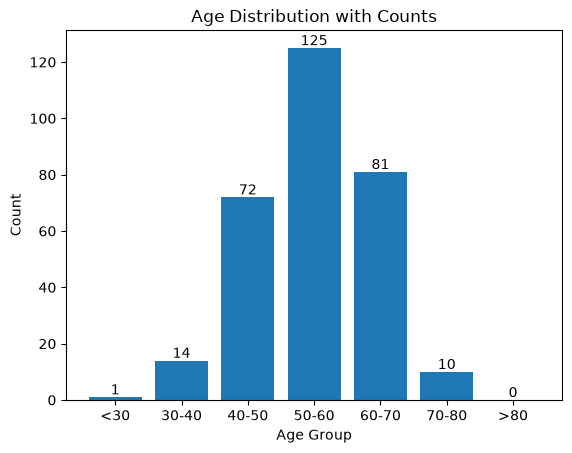

In [42]:
import numpy as np

counts, bin_edges = np.histogram(df['age'], bins=[0,30,40,50,60,70,80,100])
plt.bar(range(len(counts)), counts, tick_label=["<30","30-40","40-50","50-60","60-70","70-80",">80"])

# Annotate
for i, v in enumerate(counts):
    plt.text(i, v + 1, str(v), ha='center')

plt.xlabel("Age Group")
plt.ylabel("Count")
plt.title("Age Distribution with Counts")
plt.show()


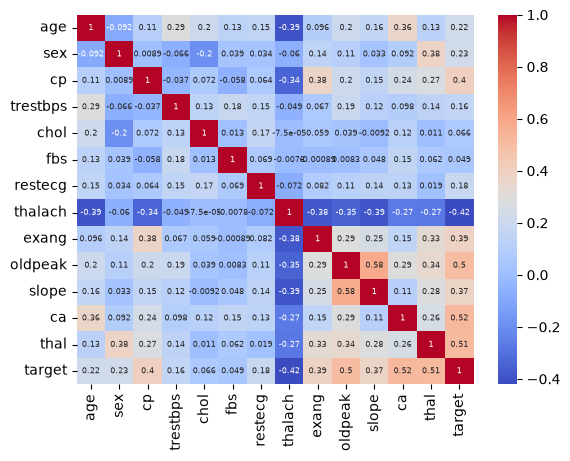

In [43]:
import seaborn as sns

#plt.figure(figsize=(12,8))
sns.heatmap(df_clean.corr(), annot=True, cmap="coolwarm", annot_kws={"size":6})
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.show()

* The correlation between "target" and "thalach" is peak negative.
* The correlation between "target" and "ca" is peak positive.
* "target" has a correlation with every feature. The correlation with "chol" and "fbs" is weak compared to other features.
* "oldpeak" and "slope" have a correlation of 0.58 and cause redundancy in linear models.
* "thalach" has multi-colinearity with multiple feature and coudl cause redundancy.

In [44]:
df_clean['target'].value_counts()

target
0    160
1     54
2     35
3     35
4     13
Name: count, dtype: int64

In [45]:
print("Count of 0:", (df_clean['target']==0).sum())
print("Count of >0:", (df_clean['target']>0).sum())
print("Ratio of 0 and non-zero: ", (df_clean['target']==0).sum()/(df_clean['target']>0).sum())

Count of 0: 160
Count of >0: 137
Ratio of 0 and non-zero:  1.167883211678832


The ratio between zero and non-zero target values is 1.15. The labels are fairly balanced if seen as zero as non-zero.

In [46]:
#Create a new binary target column
df_clean['target_binary'] = df_clean['target'].apply(lambda x: 0 if x == 0 else 1)
print(df_clean['target_binary'].value_counts())

target_binary
0    160
1    137
Name: count, dtype: int64


In [47]:
import pandas as pd

# Define bins and labels
bins = [0, 30, 40, 50, 60, 70, 80, 100]   # bin edges
labels = [1, 2, 3, 4, 5, 6, 7]            # encoded labels

# Create new column
df_clean['age_bin'] = pd.cut(df_clean['age'], bins=bins, labels=labels, right=False)

# Check distribution
print(df_clean['age_bin'].value_counts())

age_dummies = pd.get_dummies(df_clean['age_bin'], prefix='age')
df_clean = pd.concat([df_clean, age_dummies], axis=1)
print(df_clean.info())

age_bin
4    121
5     81
3     71
2     13
6     10
1      1
7      0
Name: count, dtype: int64
<class 'pandas.DataFrame'>
Index: 297 entries, 0 to 301
Data columns (total 23 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   age            297 non-null    int64   
 1   sex            297 non-null    int64   
 2   cp             297 non-null    int64   
 3   trestbps       297 non-null    int64   
 4   chol           297 non-null    int64   
 5   fbs            297 non-null    int64   
 6   restecg        297 non-null    int64   
 7   thalach        297 non-null    int64   
 8   exang          297 non-null    int64   
 9   oldpeak        297 non-null    float64 
 10  slope          297 non-null    int64   
 11  ca             297 non-null    float64 
 12  thal           297 non-null    float64 
 13  target         297 non-null    int64   
 14  target_binary  297 non-null    int64   
 15  age_bin        297 non-null    category
 16 

         trestbps        chol     thalach
count  303.000000  303.000000  303.000000
mean   131.689769  246.693069  149.607261
std     17.599748   51.776918   22.875003
min     94.000000  126.000000   71.000000
25%    120.000000  211.000000  133.500000
50%    130.000000  241.000000  153.000000
75%    140.000000  275.000000  166.000000
max    200.000000  564.000000  202.000000


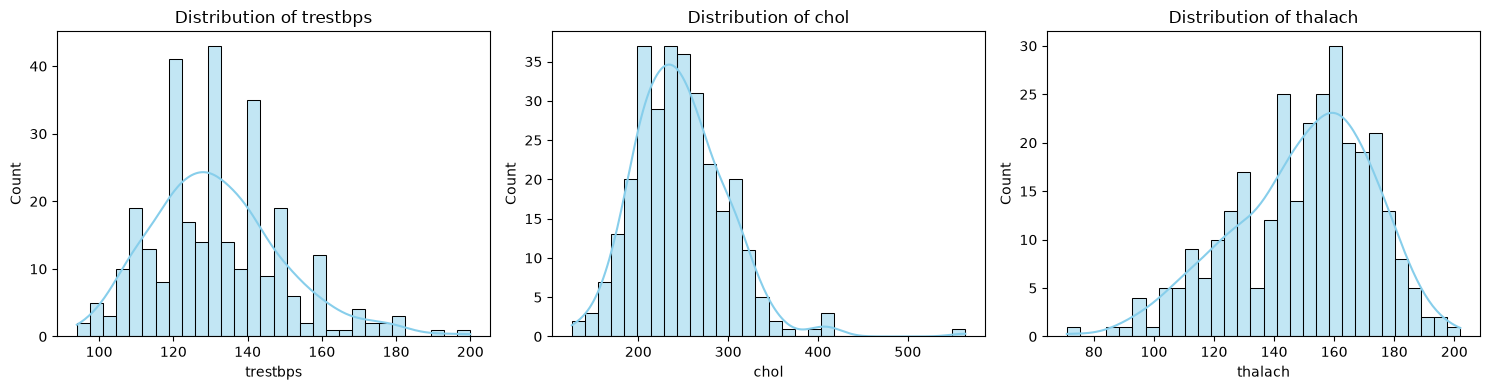

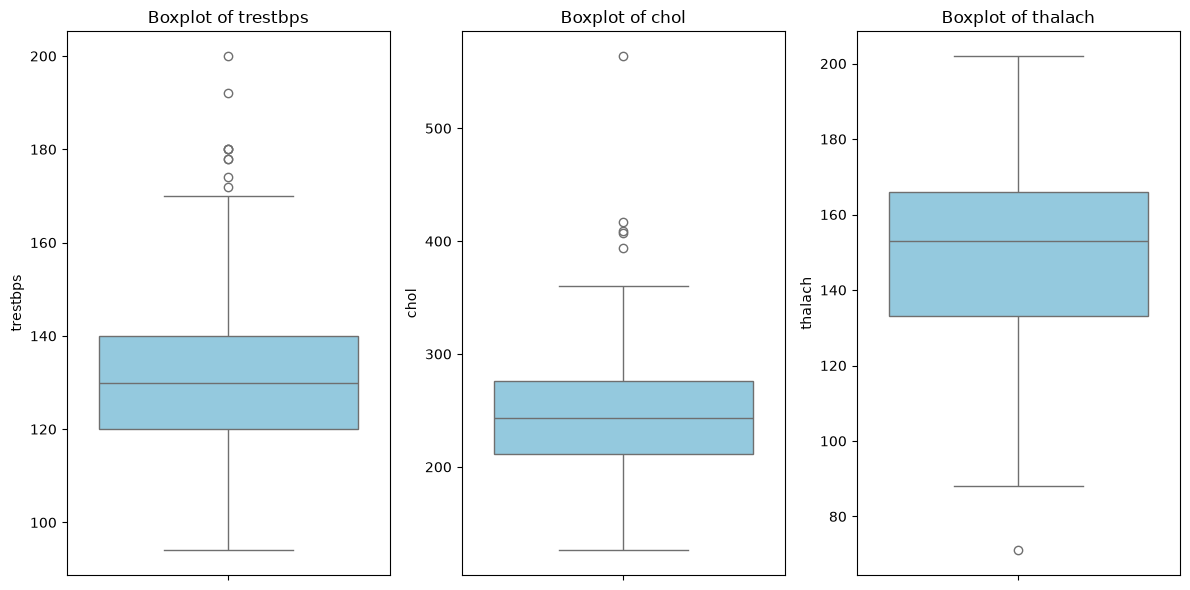

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

features = ['trestbps', 'chol', 'thalach']
print(df[features].describe())
plt.figure(figsize=(15, 4))

for i, col in enumerate(features, 1):
    plt.subplot(1, 3, i)
    sns.histplot(df_clean[col], kde=True, bins=30, color='skyblue')
    plt.title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))

for i, col in enumerate(features, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df_clean[col], color='skyblue')
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

* "trestbps" follows a normal distribution. Standardizing the feature would be useful
* "chol" is right skewed and "thalach" is left skewed.
* All the three features have outlier samples. Hence Normalization is not a preferred approach. StandardScaler can be applied

In [49]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Apply log transform to skewed features
df_clean['chol_log'] = np.log1p(df_clean['chol'])      # log(1+x) avoids issues with 0
df_clean['thalach_log'] = np.log1p(df_clean['thalach'])

# Standardize all three (trestbps directly, chol_log, thalach_log)
scaler = StandardScaler()
df_clean[['trestbps_scaled','chol_scaled','thalach_scaled']] = scaler.fit_transform(
    df_clean[['trestbps','chol_log','thalach_log']]
)

print(df_clean.describe())

              age         sex          cp    trestbps        chol         fbs  \
count  297.000000  297.000000  297.000000  297.000000  297.000000  297.000000   
mean    54.542088    0.676768    3.158249  131.693603  247.350168    0.144781   
std      9.049736    0.468500    0.964859   17.762806   51.997583    0.352474   
min     29.000000    0.000000    1.000000   94.000000  126.000000    0.000000   
25%     48.000000    0.000000    3.000000  120.000000  211.000000    0.000000   
50%     56.000000    1.000000    3.000000  130.000000  243.000000    0.000000   
75%     61.000000    1.000000    4.000000  140.000000  276.000000    0.000000   
max     77.000000    1.000000    4.000000  200.000000  564.000000    1.000000   

          restecg     thalach       exang     oldpeak       slope          ca  \
count  297.000000  297.000000  297.000000  297.000000  297.000000  297.000000   
mean     0.996633  149.599327    0.326599    1.055556    1.602694    0.676768   
std      0.994914   22.9415

In [51]:
print(df_clean.columns)

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target', 'target_binary',
       'age_bin', 'age_1', 'age_2', 'age_3', 'age_4', 'age_5', 'age_6',
       'age_7', 'chol_log', 'thalach_log', 'trestbps_scaled', 'chol_scaled',
       'thalach_scaled'],
      dtype='str')


In [53]:
final_features = ['age_bin', 'sex', 'cp', 'trestbps_scaled', 'chol_scaled', 'fbs', 'restecg', 'thalach_scaled',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target', 'target_binary']
df_final = df_clean[final_features]
print(df_final.describe())

              sex          cp  trestbps_scaled   chol_scaled         fbs  \
count  297.000000  297.000000     2.970000e+02  2.970000e+02  297.000000   
mean     0.676768    3.158249     4.904420e-16 -6.937959e-16    0.144781   
std      0.468500    0.964859     1.001688e+00  1.001688e+00    0.352474   
min      0.000000    1.000000    -2.125634e+00 -3.202774e+00    0.000000   
25%      0.000000    3.000000    -6.594306e-01 -6.776566e-01    0.000000   
50%      1.000000    3.000000    -9.550637e-02  1.513515e-02    0.000000   
75%      1.000000    4.000000     4.684179e-01  6.402519e-01    0.000000   
max      1.000000    4.000000     3.851964e+00  4.152991e+00    1.000000   

          restecg  thalach_scaled       exang     oldpeak       slope  \
count  297.000000    2.970000e+02  297.000000  297.000000  297.000000   
mean     0.996633    3.947460e-16    0.326599    1.055556    1.602694   
std      0.994914    1.001688e+00    0.469761    1.166123    0.618187   
min      0.000000   -4.

In [54]:
df_final['target_binary'].value_counts(normalize=True)

target_binary
0    0.538721
1    0.461279
Name: proportion, dtype: float64

In [56]:
import os

# Go up one level from /notebooks to project root, then into /data
save_path = os.path.join("..", "data", "df_final.csv")

# Ensure /data folder exists
os.makedirs(os.path.dirname(save_path), exist_ok=True)

# Save the DataFrame
df_final.to_csv(save_path, index=False)

print(f"Data saved to {save_path}")



Data saved to ..\data\df_final.csv
